# Exploratory Data Analysis
Look at the clean BRFSS 2023 data before modelling. Figures are sized for an IEEE two column paper.

In [1]:
%pip install pandas numpy matplotlib seaborn

In [2]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

In [3]:
processed_data_folder = "../../data/processed"
figures_folder = "../../results/figures"
tables_folder = "../../results/tables"
os.makedirs(figures_folder, exist_ok=True)
os.makedirs(tables_folder, exist_ok=True)

clean_data = pd.read_csv(processed_data_folder + "/diabetes_clean.csv")
print(clean_data.shape)

(418492, 19)


## Plot settings

In [4]:
# IEEE column widths in inches
single_column = 3.5
double_column = 7.16

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "grid.color": "#e0e0e0",
    "grid.linewidth": 0.5,
    "legend.frameon": False,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,
    "pdf.fonttype": 42,
})

blue = "#2a78d6"
orange = "#eb6834"
grey = "#b0b0b0"
dark_grey = "#52514e"


# white box behind the numbers so the dashed line does not run through them
def label_bars(ax, bars):
    labels = ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=6)
    for label in labels:
        label.set_bbox({"facecolor": "white", "edgecolor": "none", "pad": 1.5})
        label.set_zorder(5)


# png for Word, pdf for LaTeX
def save_figure(name):
    plt.savefig(figures_folder + "/" + name + ".png")
    plt.savefig(figures_folder + "/" + name + ".pdf")

In [5]:
feature_labels = {
    "high_bp": "High blood pressure",
    "high_chol": "High cholesterol",
    "chol_check": "Cholesterol check",
    "bmi": "BMI",
    "smoker": "Smoker",
    "stroke": "Stroke",
    "heart_disease": "Heart disease",
    "phys_activity": "Physical activity",
    "cost_barrier": "Cost barrier",
    "diff_walk": "Difficulty walking",
    "has_insurance": "Health insurance",
    "gen_health": "General health",
    "mental_health_days": "Poor mental health days",
    "physical_health_days": "Poor physical health days",
    "sex": "Sex (male)",
    "age_group": "Age group",
    "education": "Education",
    "income": "Income",
}

age_labels = ["18-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54",
              "55-59", "60-64", "65-69", "70-74", "75-79", "80+"]
health_labels = ["Excellent", "Very good", "Good", "Fair", "Poor"]
education_labels = ["No high school", "High school", "Some college", "College graduate"]
income_labels = ["<15k", "15-25k", "25-35k", "35-50k", "50-100k", "100-200k", "200k+"]

overall_rate = clean_data["diabetes"].mean() * 100
print("Overall diabetes rate:", round(overall_rate, 2), "%")

Overall diabetes rate: 14.29 %


## Class balance

In [6]:
class_counts = clean_data["diabetes"].value_counts().sort_index()
class_percent = clean_data["diabetes"].value_counts(normalize=True).sort_index() * 100
print(class_counts)
print(class_percent.round(2))

diabetes
0    358706
1     59786
Name: count, dtype: int64
diabetes
0    85.71
1    14.29
Name: proportion, dtype: float64


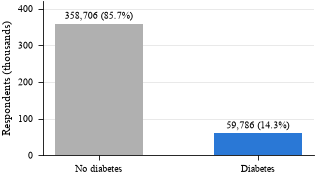

In [7]:
fig, ax = plt.subplots(figsize=(single_column, 2.0))
bars = ax.bar(["No diabetes", "Diabetes"], class_counts / 1000, color=[grey, blue], width=0.55)

bar_text = []
for count, percent in zip(class_counts, class_percent):
    bar_text.append(f"{count:,} ({percent:.1f}%)")
ax.bar_label(bars, labels=bar_text, padding=2, fontsize=7)

ax.set_ylabel("Respondents (thousands)")
ax.set_ylim(0, 420)
ax.yaxis.grid(True)
ax.set_axisbelow(True)
save_figure("fig_class_balance")
plt.show()

## Missing values

In [8]:
missing_percent = clean_data.isna().mean() * 100
missing_percent = missing_percent[missing_percent > 0].sort_values()
missing_percent.index = [feature_labels[name] for name in missing_percent.index]
missing_percent.round(2)

Stroke                        0.28
General health                0.28
Physical activity             0.28
Cost barrier                  0.33
High blood pressure           0.39
Education                     0.51
Heart disease                 0.97
Age group                     1.77
Poor mental health days       1.82
Poor physical health days     2.43
Difficulty walking            4.10
Health insurance              4.29
Smoker                        5.20
Cholesterol check             6.11
BMI                           9.30
High cholesterol             12.76
Income                       19.92
dtype: float64

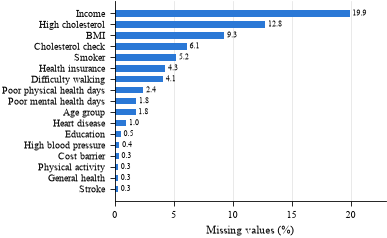

In [9]:
fig, ax = plt.subplots(figsize=(single_column, 2.6))
bars = ax.barh(missing_percent.index, missing_percent.values, color=blue, height=0.6)
ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=6)
ax.set_xlabel("Missing values (%)")
ax.set_xlim(0, 23)
ax.xaxis.grid(True)
ax.set_axisbelow(True)
save_figure("fig_missing_values")
plt.show()

In [10]:
# most of the missing high cholesterol answers come from people who never had it checked
pd.crosstab(clean_data["high_chol"].isna(), clean_data["chol_check"], dropna=False)

chol_check,0.0,1.0,NaN
high_chol,,,
False,12453,352623,0
True,25013,2839,25564


## Feature summary by diabetes status

In [11]:
feature_columns = list(feature_labels.keys())

feature_summary = clean_data.groupby("diabetes")[feature_columns].mean().T
feature_summary.columns = ["no_diabetes_mean", "diabetes_mean"]
feature_summary["missing_percent"] = clean_data[feature_columns].isna().mean() * 100
feature_summary.index = [feature_labels[name] for name in feature_summary.index]
feature_summary = feature_summary.round(3)

feature_summary.to_csv(tables_folder + "/table_feature_summary.csv")
feature_summary

,no_diabetes_mean,diabetes_mean,missing_percent
High blood pressure,0.350,0.735,0.393
High cholesterol,0.374,0.643,12.764
Cholesterol check,0.891,0.984,6.109
BMI,27.865,31.612,9.298
Smoker,0.374,0.456,5.203
Stroke,0.033,0.097,0.275
Heart disease,0.064,0.205,0.974
Physical activity,0.780,0.599,0.277
Cost barrier,0.085,0.083,0.334
Difficulty walking,0.125,0.357,4.098


In [12]:
clean_data.groupby("diabetes")[["bmi", "mental_health_days", "physical_health_days"]].median()

,bmi,mental_health_days,physical_health_days
diabetes,,,
0,26.78,0.0,0.0
1,30.42,0.0,1.0


## BMI distribution

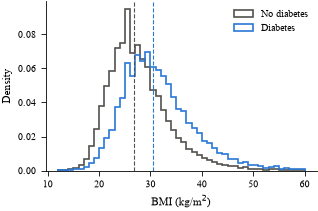

Median BMI, no diabetes: 26.78
Median BMI, diabetes: 30.42


In [13]:
no_diabetes_bmi = clean_data.loc[clean_data["diabetes"] == 0, "bmi"].dropna()
diabetes_bmi = clean_data.loc[clean_data["diabetes"] == 1, "bmi"].dropna()

# a few very high values, cut the plot at 60 so the shape is visible
bmi_bins = np.arange(12, 61, 1)

fig, ax = plt.subplots(figsize=(single_column, 2.2))
ax.hist(no_diabetes_bmi, bins=bmi_bins, density=True, histtype="step", linewidth=1.2,
        color=dark_grey, label="No diabetes")
ax.hist(diabetes_bmi, bins=bmi_bins, density=True, histtype="step", linewidth=1.2,
        color=blue, label="Diabetes")
ax.axvline(no_diabetes_bmi.median(), color=dark_grey, linestyle="--", linewidth=0.8)
ax.axvline(diabetes_bmi.median(), color=blue, linestyle="--", linewidth=0.8)
ax.set_xlabel("BMI (kg/m$^2$)")
ax.set_ylabel("Density")
ax.legend()
save_figure("fig_bmi_distribution")
plt.show()

print("Median BMI, no diabetes:", no_diabetes_bmi.median())
print("Median BMI, diabetes:", diabetes_bmi.median())

## Diabetes rate for the yes/no features

In [14]:
binary_features = ["high_bp", "high_chol", "heart_disease", "stroke", "diff_walk",
                   "smoker", "phys_activity", "cost_barrier", "has_insurance", "chol_check"]

rows = []
for column in binary_features:
    rate_no = clean_data.loc[clean_data[column] == 0, "diabetes"].mean() * 100
    rate_yes = clean_data.loc[clean_data[column] == 1, "diabetes"].mean() * 100
    rows.append({"feature": feature_labels[column], "rate_no": rate_no, "rate_yes": rate_yes})

binary_rates = pd.DataFrame(rows).sort_values("rate_yes")
binary_rates.to_csv(tables_folder + "/table_binary_feature_rates.csv", index=False)
binary_rates.round(2)

,feature,rate_no,rate_yes
6,Physical activity,23.33,11.32
7,Cost barrier,14.31,13.99
8,Health insurance,7.71,14.71
9,Cholesterol check,2.39,15.99
5,Smoker,12.72,16.97
1,High cholesterol,9.47,23.96
0,High blood pressure,6.35,25.93
4,Difficulty walking,10.95,32.27
3,Stroke,13.44,32.95
2,Heart disease,12.30,34.57


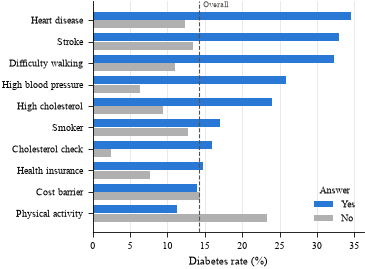

In [15]:
positions = np.arange(len(binary_rates))

fig, ax = plt.subplots(figsize=(single_column, 3.0))
ax.barh(positions + 0.2, binary_rates["rate_yes"], height=0.38, color=blue, label="Yes")
ax.barh(positions - 0.2, binary_rates["rate_no"], height=0.38, color=grey, label="No")
ax.axvline(overall_rate, color=dark_grey, linestyle="--", linewidth=0.8)
ax.text(overall_rate + 0.5, len(binary_rates) - 0.4, "Overall", fontsize=6, color=dark_grey)

ax.set_yticks(positions)
ax.set_yticklabels(binary_rates["feature"])
ax.set_xlabel("Diabetes rate (%)")
ax.xaxis.grid(True)
ax.set_axisbelow(True)
ax.legend(loc="lower right", title="Answer", title_fontsize=7)
save_figure("fig_binary_feature_rates")
plt.show()

## Diabetes rate by general health and BMI category

In [16]:
clean_data["bmi_category"] = pd.cut(
    clean_data["bmi"],
    bins=[0, 18.5, 25, 30, 35, 40, 100],
    labels=["<18.5", "18.5-25", "25-30", "30-35", "35-40", "40+"],
    right=False,
)

health_rates = clean_data.groupby("gen_health")["diabetes"].mean() * 100
bmi_rates = clean_data.groupby("bmi_category", observed=True)["diabetes"].mean() * 100
print(health_rates.round(2))
print(bmi_rates.round(2))

gen_health
1.0     3.18
2.0     7.54
3.0    16.64
4.0    28.72
5.0    37.09
Name: diabetes, dtype: float64
bmi_category
<18.5       5.41
18.5-25     6.99
25-30      12.85
30-35      20.04
35-40      26.10
40+        30.89
Name: diabetes, dtype: float64


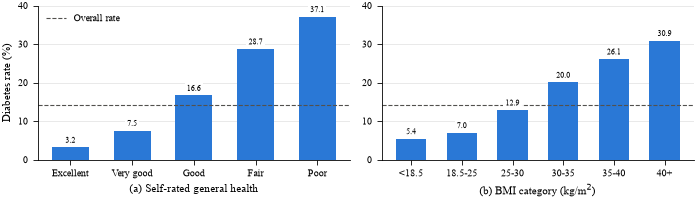

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(double_column, 2.2))

bars = ax1.bar(health_labels, health_rates.values, color=blue, width=0.6)
label_bars(ax1, bars)
ax1.set_xlabel("(a) Self-rated general health")
ax1.set_ylabel("Diabetes rate (%)")

bars = ax2.bar(bmi_rates.index.astype(str), bmi_rates.values, color=blue, width=0.6)
label_bars(ax2, bars)
ax2.set_xlabel("(b) BMI category (kg/m$^2$)")

for ax in [ax1, ax2]:
    ax.axhline(overall_rate, color=dark_grey, linestyle="--", linewidth=0.8, label="Overall rate")
    ax.set_ylim(0, 40)
    ax.yaxis.grid(True)
    ax.set_axisbelow(True)

ax1.legend(loc="upper left")
plt.tight_layout()
save_figure("fig_rate_health_bmi")
plt.show()

## Diabetes rate by age and sex

In [18]:
age_sex_rates = clean_data.groupby(["age_group", "sex"])["diabetes"].mean().unstack() * 100
age_sex_rates.columns = ["Female", "Male"]
age_sex_rates.index = age_labels
age_sex_rates.round(2)

,Female,Male
18-24,1.31,1.08
25-29,1.80,1.67
30-34,2.98,2.36
35-39,4.88,3.93
40-44,6.60,6.49
45-49,10.32,10.14
50-54,13.15,14.74
55-59,16.06,18.71
60-64,18.16,20.58
65-69,19.70,22.67


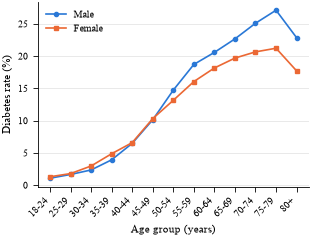

In [19]:
fig, ax = plt.subplots(figsize=(single_column, 2.4))
x = np.arange(len(age_labels))
ax.plot(x, age_sex_rates["Male"], marker="o", markersize=3, linewidth=1.2, color=blue, label="Male")
ax.plot(x, age_sex_rates["Female"], marker="s", markersize=3, linewidth=1.2, color=orange, label="Female")

ax.set_xticks(x)
ax.set_xticklabels(age_labels, rotation=45, ha="right")
ax.set_xlabel("Age group (years)")
ax.set_ylabel("Diabetes rate (%)")
ax.yaxis.grid(True)
ax.set_axisbelow(True)
ax.legend(loc="upper left")
save_figure("fig_rate_age_sex")
plt.show()

## Subgroup sizes

In [20]:
# number of diabetes cases in each 5 year age group, the youngest groups are small
cases_by_age = clean_data.groupby("age_group")["diabetes"].agg(["size", "sum"])
cases_by_age.columns = ["people", "cases"]
cases_by_age.index = age_labels
cases_by_age

,people,cases
18-24,25876,305
25-29,20763,359
30-34,24057,640
35-39,26135,1152
40-44,27392,1792
45-49,26121,2673
50-54,30070,4178
55-59,32921,5699
60-64,40381,7790
65-69,44401,9352


In [21]:
# wider age bands for the subgroup analysis
clean_data["age_band"] = pd.cut(
    clean_data["age_group"],
    bins=[0, 3, 6, 9, 13],
    labels=["18-34", "35-49", "50-64", "65+"],
)
clean_data["sex_label"] = clean_data["sex"].map({1: "Male", 0: "Female"})

subgroups = clean_data.groupby(["age_band", "sex_label"], observed=True)["diabetes"].agg(["size", "sum", "mean"])
subgroups.columns = ["people", "cases", "rate"]
subgroups["rate"] = (subgroups["rate"] * 100).round(2)

subgroups.to_csv(tables_folder + "/table_subgroups.csv")
subgroups

people  cases   rate
age_band sex_label                      
18-34    Female      32489    668   2.06
         Male        38207    636   1.66
35-49    Female      40672   2965   7.29
         Male        38976   2652   6.80
50-64    Female      54909   8806  16.04
         Male        48463   8861  18.28
65+      Female      87799  17356  19.77
         Male        69576  16921  24.32

## Income and education

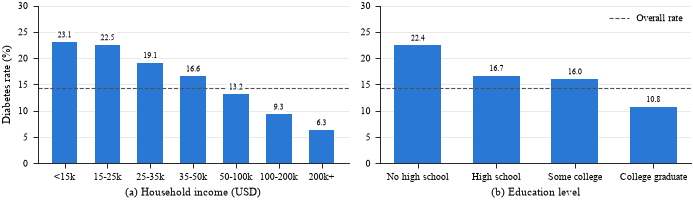

In [22]:
income_rates = clean_data.groupby("income")["diabetes"].mean() * 100
education_rates = clean_data.groupby("education")["diabetes"].mean() * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(double_column, 2.2))

bars = ax1.bar(income_labels, income_rates.values, color=blue, width=0.6)
label_bars(ax1, bars)
ax1.set_xlabel("(a) Household income (USD)")
ax1.set_ylabel("Diabetes rate (%)")

bars = ax2.bar(education_labels, education_rates.values, color=blue, width=0.6)
label_bars(ax2, bars)
ax2.set_xlabel("(b) Education level")

for ax in [ax1, ax2]:
    ax.axhline(overall_rate, color=dark_grey, linestyle="--", linewidth=0.8, label="Overall rate")
    ax.set_ylim(0, 30)
    ax.yaxis.grid(True)
    ax.set_axisbelow(True)

ax2.legend(loc="upper right")
plt.tight_layout()
save_figure("fig_rate_income_education")
plt.show()

## Correlation

In [23]:
# Spearman because most of the features are ordinal or yes/no
correlation = clean_data[["diabetes"] + feature_columns].corr(method="spearman")

short_labels = ["Diabetes"] + [feature_labels[name] for name in feature_columns]
correlation.index = short_labels
correlation.columns = short_labels

correlation_with_target = correlation["Diabetes"].drop("Diabetes").sort_values(ascending=False)
correlation_with_target.round(3).to_csv(tables_folder + "/table_correlation_with_diabetes.csv")
correlation_with_target.round(3)

High blood pressure          0.275
General health               0.260
Difficulty walking           0.222
Age group                    0.213
BMI                          0.203
High cholesterol             0.197
Heart disease                0.177
Poor physical health days    0.139
Cholesterol check            0.113
Stroke                       0.112
Smoker                       0.059
Health insurance             0.045
Sex (male)                   0.015
Cost barrier                -0.003
Poor mental health days     -0.003
Education                   -0.091
Income                      -0.140
Physical activity           -0.148
Name: Diabetes, dtype: float64

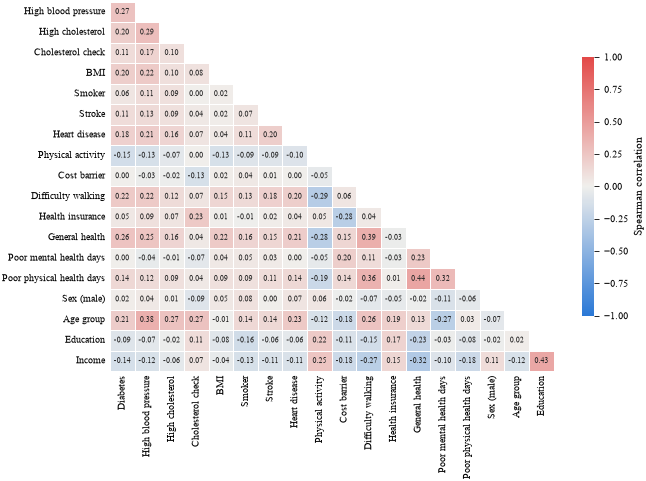

In [24]:
blue_red = LinearSegmentedColormap.from_list("blue_red", ["#2a78d6", "#f0efec", "#e34948"])

# the first row and last column are empty once the upper half is hidden
# adding 0.0 turns -0.00 into 0.00
plot_correlation = correlation.round(2).iloc[1:, :-1] + 0.0
upper_triangle = np.triu(np.ones(plot_correlation.shape, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(double_column, 4.8))
sns.heatmap(
    plot_correlation,
    mask=upper_triangle,
    cmap=blue_red,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 5.5},
    linewidths=0.4,
    linecolor="white",
    cbar_kws={"label": "Spearman correlation", "shrink": 0.7},
    ax=ax,
)
ax.tick_params(length=0)
save_figure("fig_correlation")
plt.show()